In [60]:
import numpy as np
import matplotlib.pyplot as plt

In [82]:
# Load All Data
data_fname = '../spreadsheet_20261012.csv'
header = ["temp","eps12","L1","N1","L2","N2","M2",
          "block_size", "start_frame",
          "K2","log_K2", "SEM_K2", "SEM_log_K2",
          "phi_all_dense","phi_all_dilute","phi1_dense","phi1_dilute","phi2_dense","phi2_dilute",
          "SEM_phi_all_dense", "SEM_phi_all_dilute", "SEM_phi1_dense", "SEM_phi1_dilute", "SEM_phi2_dense", "SEM_phi2_dilute",
          "rho_all_dense","rho_all_dilute","rho1_dense","rho1_dilute","rho2_dense","rho2_dilute",
          "SEM_rho_all_dense", "SEM_rho_all_dilute", "SEM_rho1_dense", "SEM_rho1_dilute", "SEM_rho2_dense", "SEM_rho2_dilute"]
data = np.genfromtxt(data_fname, delimiter=",", names=True)

# Unpack some variables
temp, eps12 = data['temp'], data['eps12']
L1, N1, L2, N2, M2 = data['L1'], data['N1'], data['L2'], data['N2'], data['M2']
phi_all_dense, phi_all_dilute = data['phi_all_dense'], data['phi_all_dilute']
phi1_dense, phi1_dilute = data['phi1_dense'], data['phi1_dilute']
phi2_dense, phi2_dilute = data['phi2_dense'], data['phi2_dilute']
K2 = data['K2']

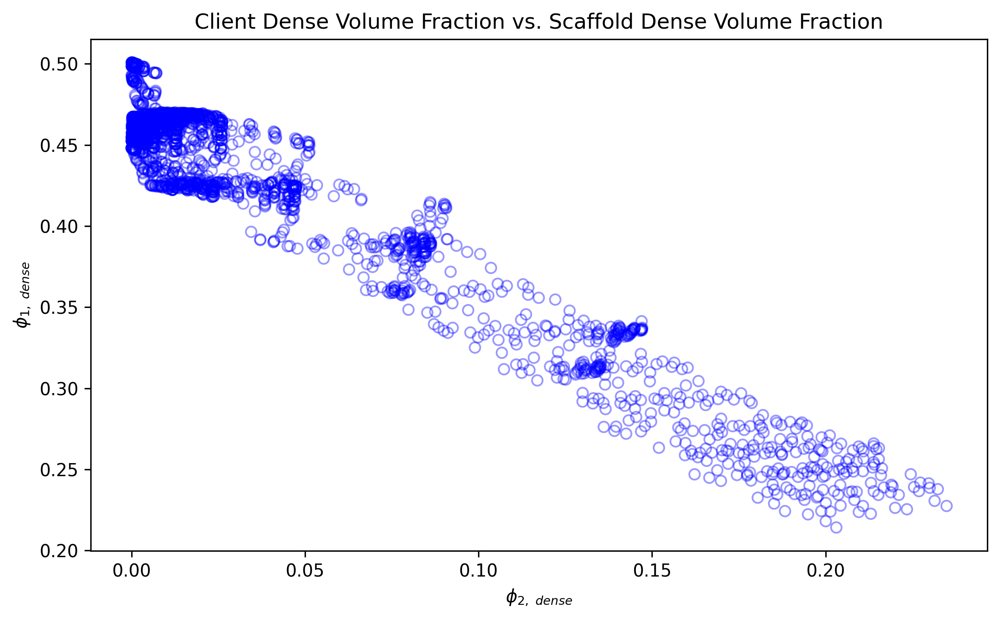

In [148]:
plt.figure(figsize=(8, 5), dpi=300)
plt.scatter(data['phi2_dense'], data['phi1_dense'], alpha=0.4, facecolors='None', edgecolors='Blue')

plt.xlabel(r"$\phi_{2,\ dense}$")
plt.ylabel(r"$\phi_{1,\ dense}$")
plt.title(r"Client Dense Volume Fraction vs. Scaffold Dense Volume Fraction")
plt.tight_layout()
plt.savefig('../2-Plots/3_1a_phi2dense_vs_phi1dense.png')
plt.show()

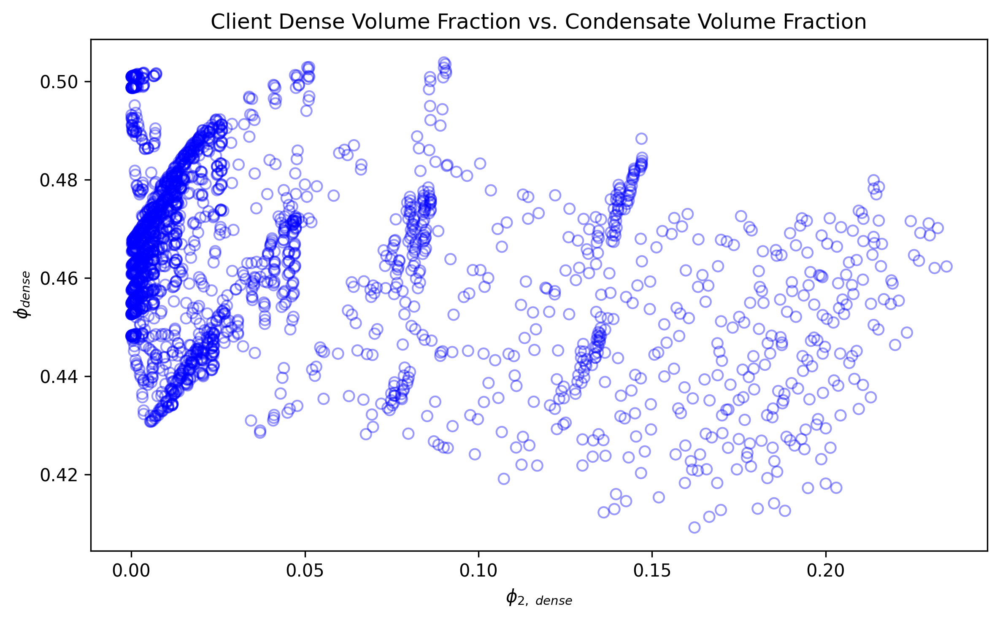

In [147]:
plt.figure(figsize=(8, 5), dpi=300)
plt.scatter(data['phi2_dense'], data['phi_all_dense'], alpha=0.4, facecolors='None', edgecolors='Blue')

plt.xlabel(r"$\phi_{2,\ dense}$")
plt.ylabel(r"$\phi_{dense}$")
plt.title(r"Client Dense Volume Fraction vs. Condensate Volume Fraction")
plt.tight_layout()
plt.savefig('../2-Plots/3_1b_phi2dense_vs_phialldense.png')
plt.show()

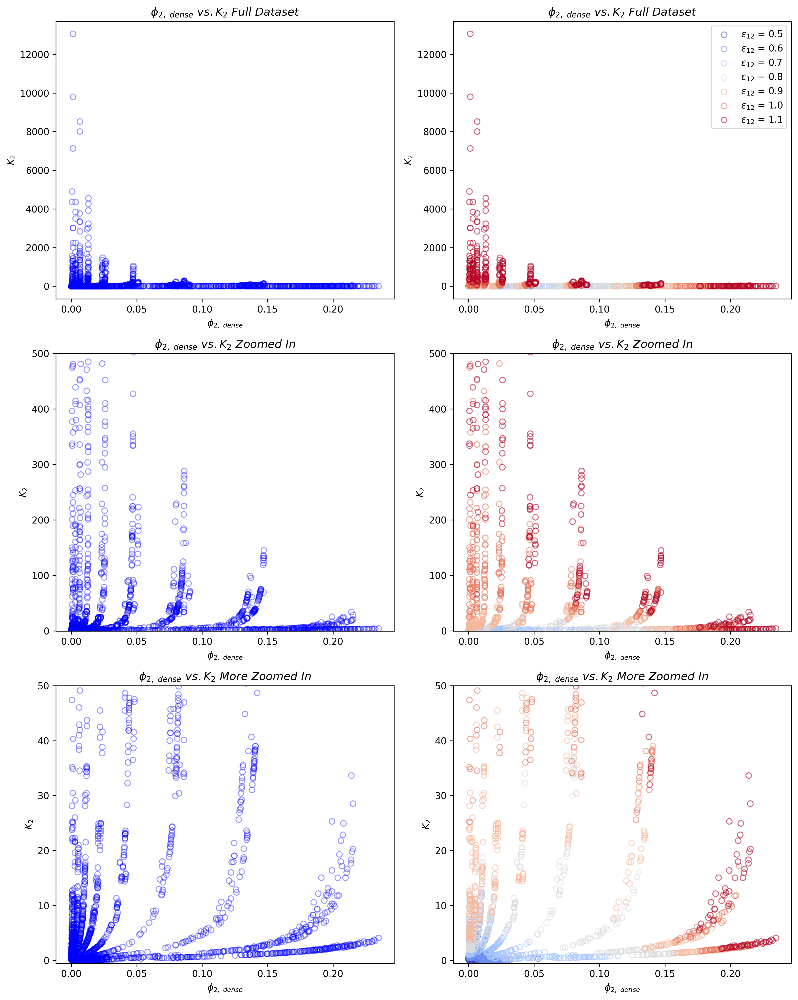

In [123]:
fig, ax = plt.subplots(3, 2, figsize=(12, 15), dpi=300)
ax[0, 0].scatter(data['phi2_dense'], data['K2'], alpha=0.4, facecolors='None', edgecolors='Blue')
ax[0, 0].set_xlabel(r"$\phi_{2,\ dense}$")
ax[0, 0].set_ylabel(r"$K_2$")
ax[0, 0].set_title(r"$\phi_{2,\ dense}\ vs. K_2\ Full\ Dataset$")

ax[1, 0].scatter(data['phi2_dense'], data['K2'], alpha=0.4, facecolors='None', edgecolors='Blue')
ax[1, 0].set_xlabel(r"$\phi_{2,\ dense}$")
ax[1, 0].set_ylabel(r"$K_2$")
ax[1, 0].set_title(r"$\phi_{2,\ dense}\ vs. K_2\ Zoomed\ In$")
ax[1, 0].set_ylim([-0.5, 500])

ax[2, 0].scatter(data['phi2_dense'], data['K2'], alpha=0.4, facecolors='None', edgecolors='Blue')
ax[2, 0].set_xlabel(r"$\phi_{2,\ dense}$")
ax[2, 0].set_ylabel(r"$K_2$")
ax[2, 0].set_title(r"$\phi_{2,\ dense}\ vs. K_2\ More\ Zoomed\ In$")
ax[2, 0].set_ylim([-0.5, 50])

eps12_values = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1]
edgecols = plt.cm.coolwarm(np.linspace(0, 1, len(eps12_values)))
for eps12, edge in zip(eps12_values, edgecols):
    indices = np.where(data['eps12'] == eps12)
    phi2_dense = data['phi2_dense'][indices]
    K2 = data['K2'][indices]
    ax[0, 1].scatter(phi2_dense, K2, alpha=0.6, facecolors='None', edgecolors=edge, label=rf'$\epsilon_{{12}}$ = {eps12:.1f}')
    ax[1, 1].scatter(phi2_dense, K2, alpha=0.6, facecolors='None', edgecolors=edge)
    ax[2, 1].scatter(phi2_dense, K2, alpha=0.6, facecolors='None', edgecolors=edge)

ax[0, 1].legend()
ax[0, 1].set_xlabel(r"$\phi_{2,\ dense}$")
ax[0, 1].set_ylabel(r"$K_2$")
ax[0, 1].set_title(r"$\phi_{2,\ dense}\ vs. K_2\ Full\ Dataset$")
ax[1, 1].set_xlabel(r"$\phi_{2,\ dense}$")
ax[1, 1].set_ylabel(r"$K_2$")
ax[1, 1].set_title(r"$\phi_{2,\ dense}\ vs. K_2\ Zoomed\ In$")
ax[1, 1].set_ylim([-0.5, 500])
ax[2, 1].set_xlabel(r"$\phi_{2,\ dense}$")
ax[2, 1].set_ylabel(r"$K_2$")
ax[2, 1].set_title(r"$\phi_{2,\ dense}\ vs. K_2\ More\ Zoomed\ In$")
ax[2, 1].set_ylim([-0.5, 50])

plt.tight_layout()
plt.savefig('../2-Plots/3_2a_phi2dense_vs_K2.png')
plt.show()

# print(np.min(data['K2']))
# print(np.max(data['K2']))

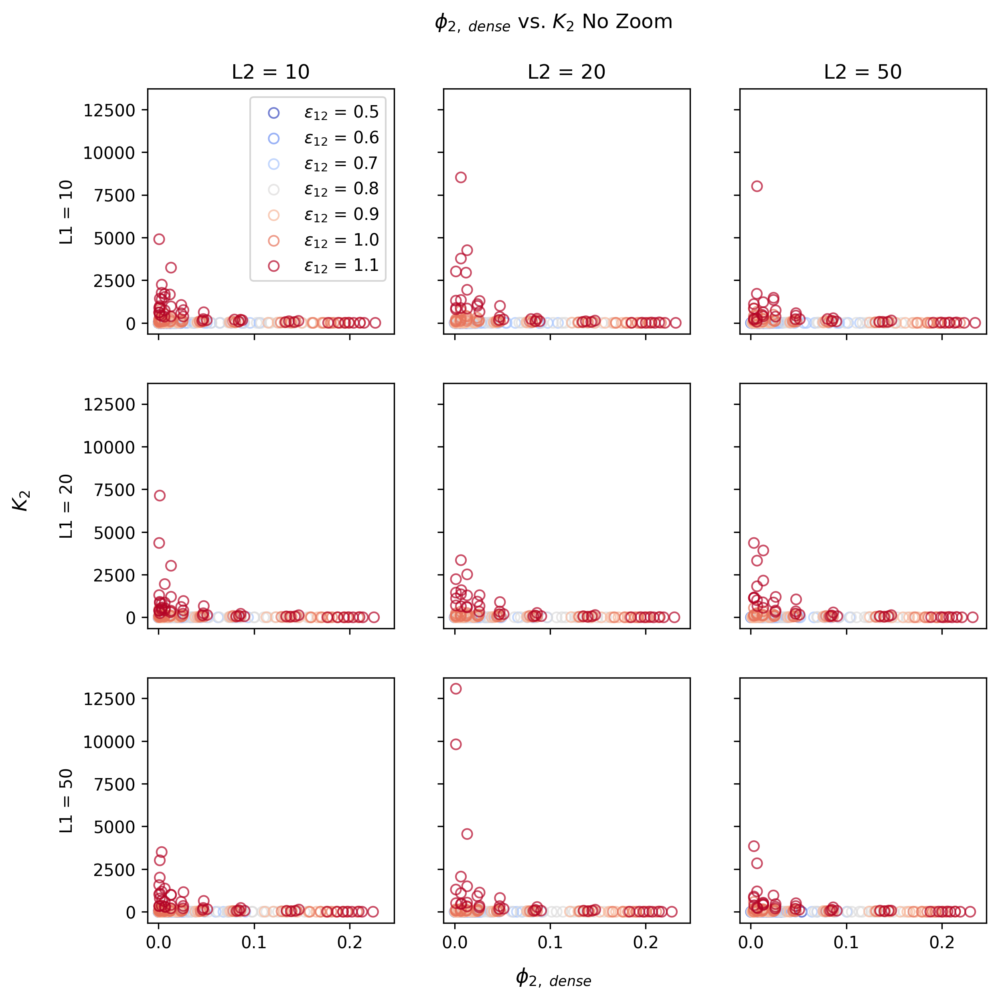

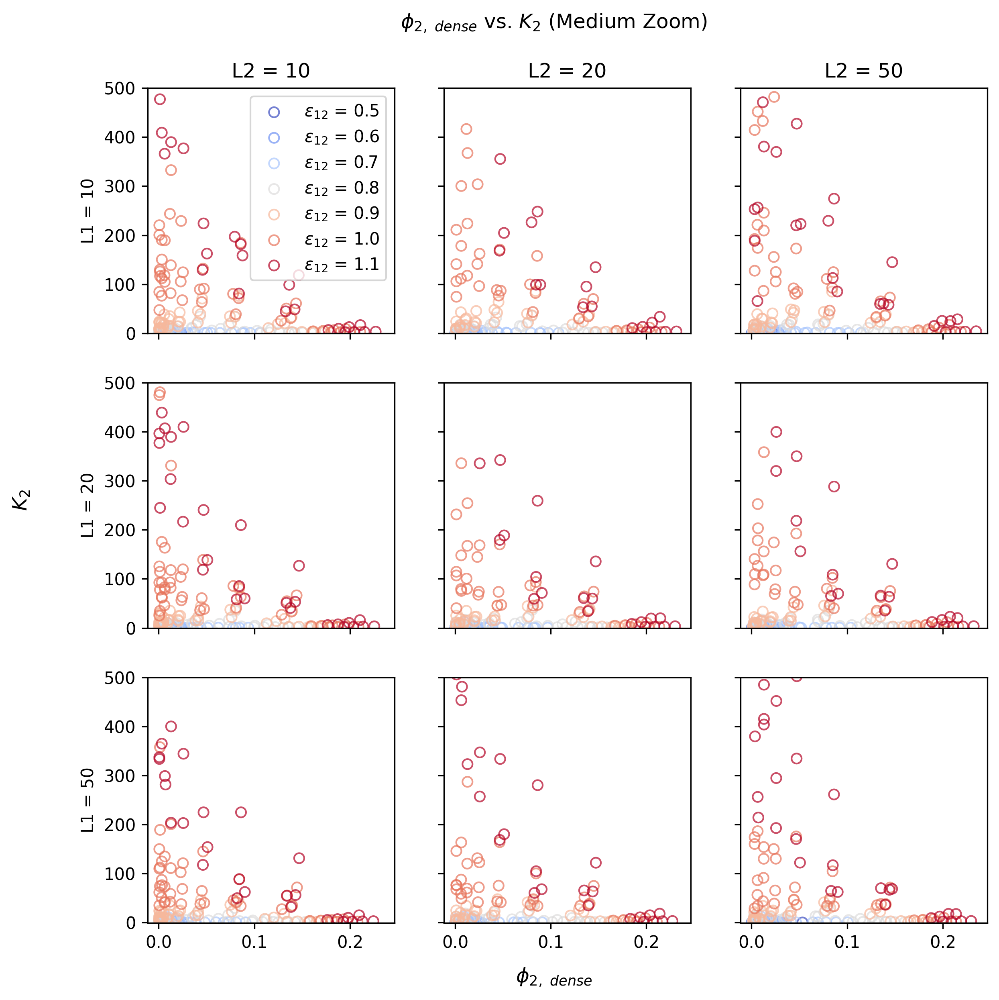

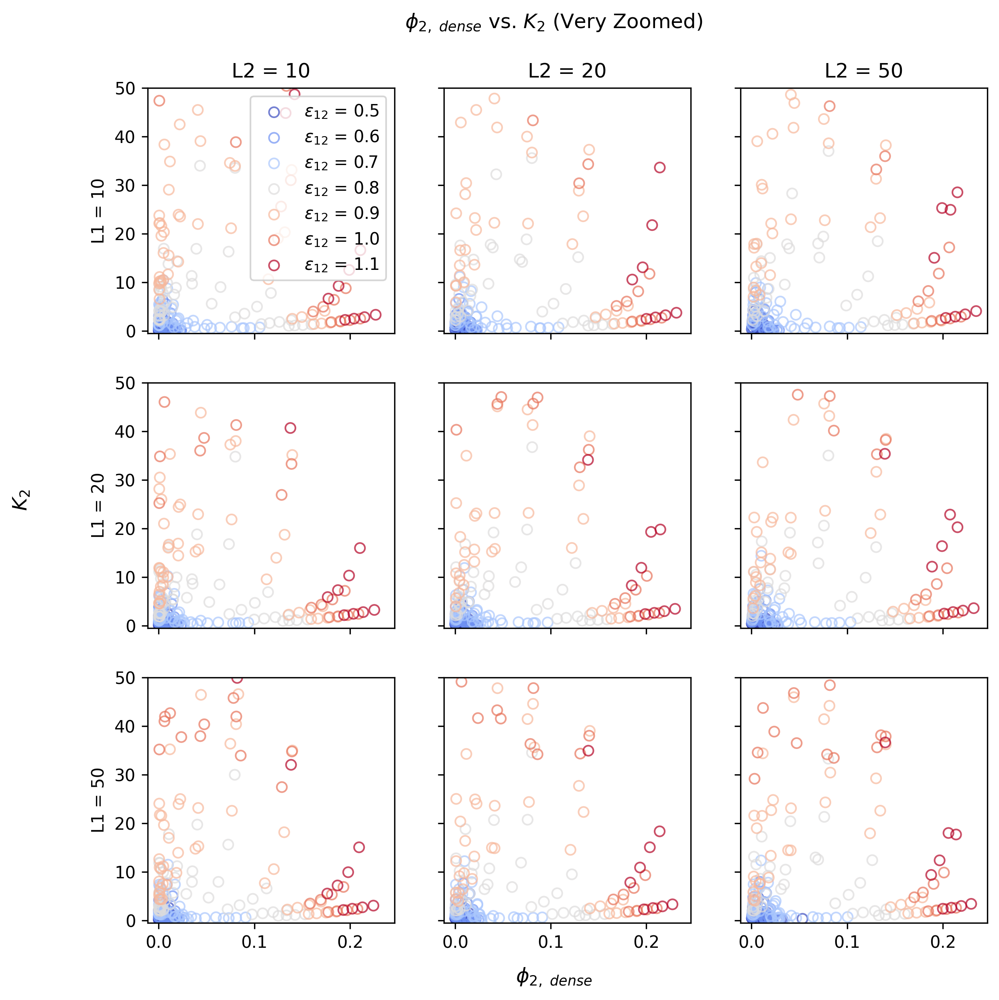

In [139]:
# No zoom; zoomed; very zoomed
def plot_phi2_K2(phi2, K2, eps12, L1, L2, zoom='very'):
    ylims = {'no': None, 'medium': 500, 'very': 50}
    ylim = ylims[zoom]
    Ls = [10, 20, 50]
    eps12s_vals = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1]

    fig, ax = plt.subplots(3, 3, figsize=(9, 9), dpi=300, sharex=True, sharey=True)

    for i, l1 in enumerate(Ls):
        ax[i, 0].set_ylabel(f'L1 = {l1}')
        for j, l2 in enumerate(Ls):
            if i == 0:
                ax[i, j].set_title(f'L2 = {l2}')
            row, col = i, j
            edgecols = plt.cm.coolwarm(np.linspace(0, 1, len(eps12s_vals)))
            for eps, edge in zip(eps12s_vals, edgecols):
                mask = np.where( (eps12 == eps) & (L1 == l1) & (L2 == l2) )
                phi2_sample, K2_sample = phi2[mask], K2[mask]
                if (i == 0) and (j == 0):
                    ax[i, j].scatter(phi2_sample, K2_sample, alpha=0.7, facecolors='None', edgecolors=edge, label=rf'$\epsilon_{{12}}$ = {eps:.1f}')
                    ax[i, j].legend()
                else:
                    ax[i, j].scatter(phi2_sample, K2_sample, alpha=0.7, facecolors='None', edgecolors=edge)

                if ylim != None:
                    ax[i, j].set_ylim([-0.5, ylim])

    fig.supylabel(r'$K_2$', x=0)
    fig.supxlabel(r'$\phi_{2,\ dense}$', y=0.05)
    if zoom == 'no':
        fig.suptitle(rf'$\phi_{{2,\ dense}}$ vs. $K_2$ No Zoom', y=0.9511)
        fig.savefig(f'../2-Plots/3_2b_phi2dense_vs_K2_noZoom.png')
    elif zoom == 'medium':
        fig.suptitle(rf'$\phi_{{2,\ dense}}$ vs. $K_2$ (Medium Zoom)', y=0.95)
        fig.savefig(f'../2-Plots/3_2b_phi2dense_vs_K2_mediumZoom.png')
    else:
        fig.suptitle(rf'$\phi_{{2,\ dense}}$ vs. $K_2$ (Very Zoomed)', y=0.95)
        fig.savefig(f'../2-Plots/3_2b_phi2dense_vs_K2_veryZoom.png')

K2 = data['K2']
phi2_dense = data['phi2_dense']
eps12 = data['eps12']
L1, L2 = data['L1'], data['L2']
plot_phi2_K2(phi2_dense, K2, eps12, L1, L2, zoom='no')
plot_phi2_K2(phi2_dense, K2, eps12, L1, L2, zoom='medium')
plot_phi2_K2(phi2_dense, K2, eps12, L1, L2, zoom='very')

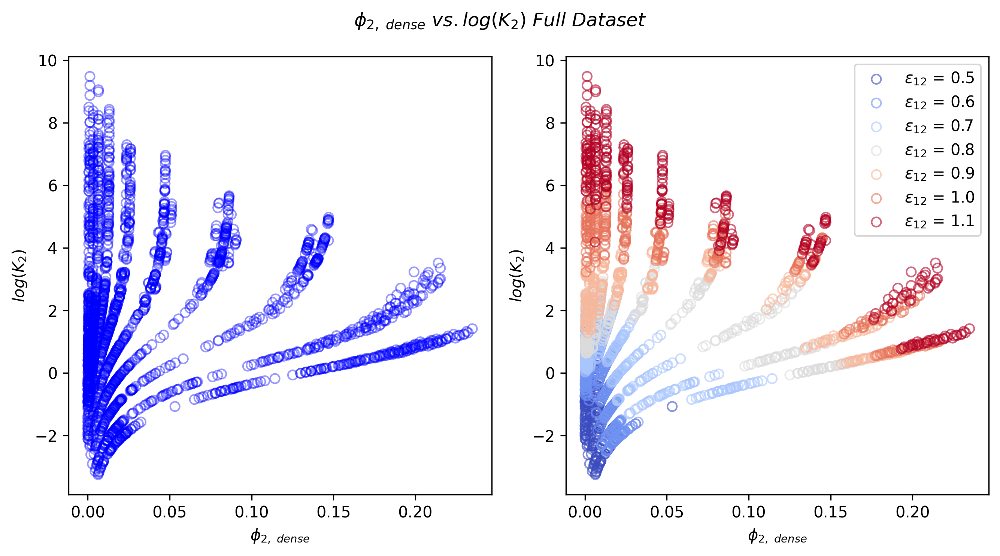

In [141]:
fig, ax = plt.subplots(1, 2, figsize=(9, 5), dpi=300)
ax[0].scatter(data['phi2_dense'], data['log_K2'], alpha=0.4, facecolors='None', edgecolors='Blue')
ax[0].set_xlabel(r"$\phi_{2,\ dense}$")
ax[0].set_ylabel(r"$log(K_2)$")

eps12_values = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1]
edgecols = plt.cm.coolwarm(np.linspace(0, 1, len(eps12_values)))
for eps12, edge in zip(eps12_values, edgecols):
    indices = np.where(data['eps12'] == eps12)
    phi2_dense = data['phi2_dense'][indices]
    logK2 = data['log_K2'][indices]
    ax[1].scatter(phi2_dense, logK2, alpha=0.6, facecolors='None', edgecolors=edge, label=rf'$\epsilon_{{12}}$ = {eps12:.1f}')

ax[1].legend()
ax[1].set_xlabel(r"$\phi_{2,\ dense}$")
ax[1].set_ylabel(r"$log(K_2)$")
fig.suptitle(r"$\phi_{2,\ dense}\ vs. log(K_2)\ Full\ Dataset$")

plt.tight_layout()
plt.savefig('../2-Plots/3_3a_phi2dense_vs_logK2.png')
plt.show()

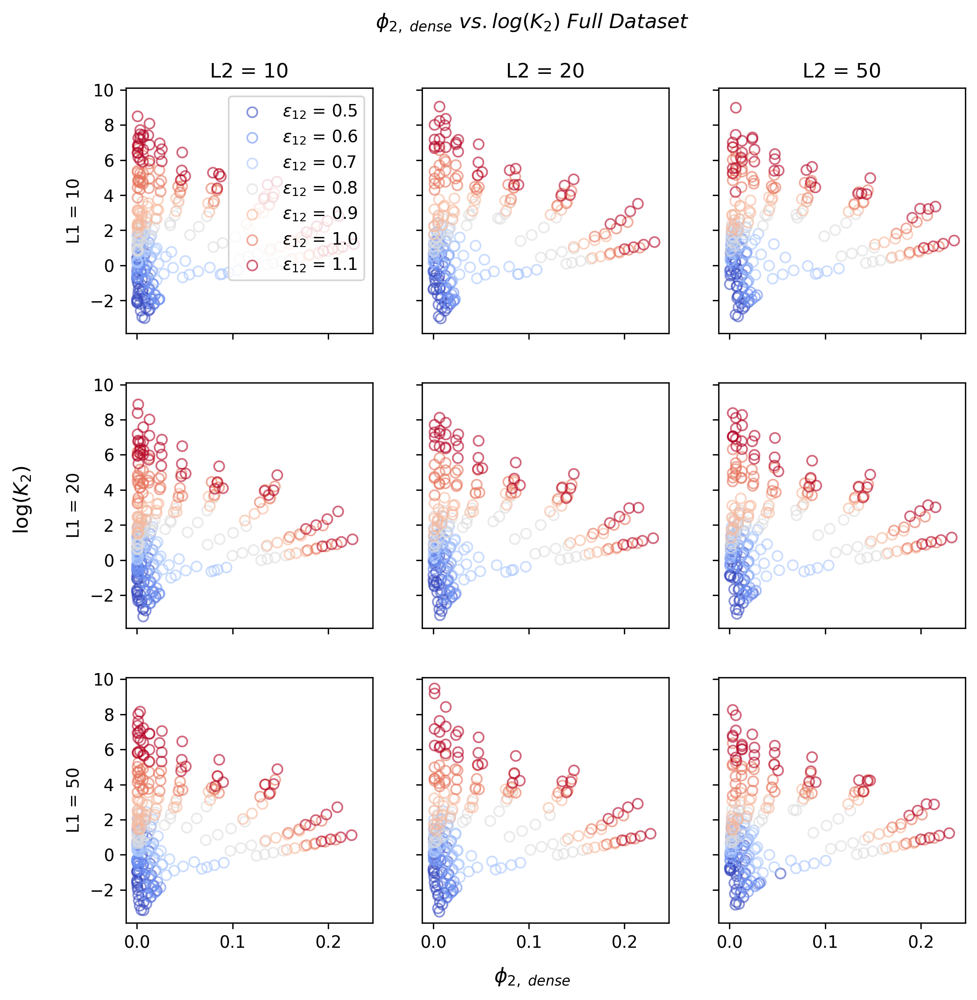

In [149]:
# phi2_dense vs. log(K2)
def plot_phi2_logK2(phi2, logK2, eps12, L1, L2):
    Ls = [10, 20, 50]
    eps12s_vals = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1]

    fig, ax = plt.subplots(3, 3, figsize=(9, 9), dpi=300, sharex=True, sharey=True)

    for i, l1 in enumerate(Ls):
        ax[i, 0].set_ylabel(f'L1 = {l1}')
        for j, l2 in enumerate(Ls):
            if i == 0:
                ax[i, j].set_title(f'L2 = {l2}')
            row, col = i, j
            edgecols = plt.cm.coolwarm(np.linspace(0, 1, len(eps12s_vals)))
            for eps, edge in zip(eps12s_vals, edgecols):
                mask = np.where( (eps12 == eps) & (L1 == l1) & (L2 == l2) )
                phi2_sample, log_K2_sample = phi2[mask], logK2[mask]
                if (i == 0) and (j == 0):
                    ax[i, j].scatter(phi2_sample, log_K2_sample, alpha=0.6, facecolors='None', edgecolors=edge, label=rf'$\epsilon_{{12}}$ = {eps:.1f}')
                    ax[i, j].legend()
                else:
                    ax[i, j].scatter(phi2_sample, log_K2_sample, alpha=0.6, facecolors='None', edgecolors=edge)

    fig.supylabel(r'$\log(K_2)$')
    fig.supxlabel(r'$\phi_{2,\ dense}$', y=0.05)
    fig.suptitle(r"$\phi_{2,\ dense}\ vs. log(K_2)\ Full\ Dataset$", y=0.95)
    fig.savefig('../2-Plots/3_3b_phi2dense_vs_logK2_rowL1_colL2.png')

logK2 = data['log_K2']
phi2_dense = data['phi2_dense']
eps12 = data['eps12']
L1, L2 = data['L1'], data['L2']
plot_phi2_logK2(phi2_dense, logK2, eps12, L1, L2)

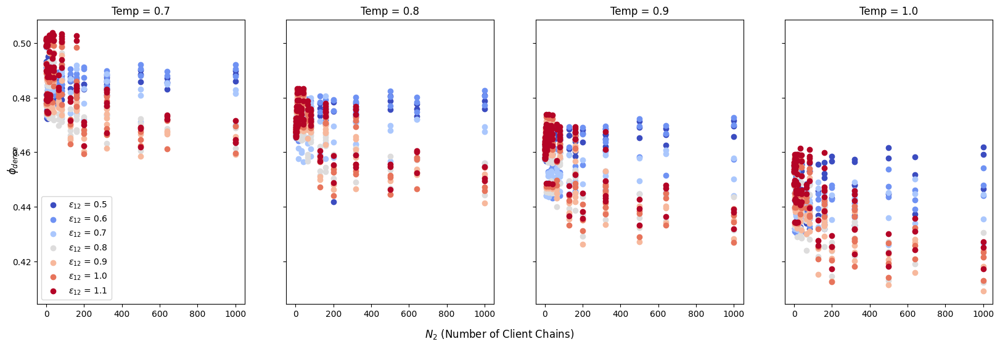

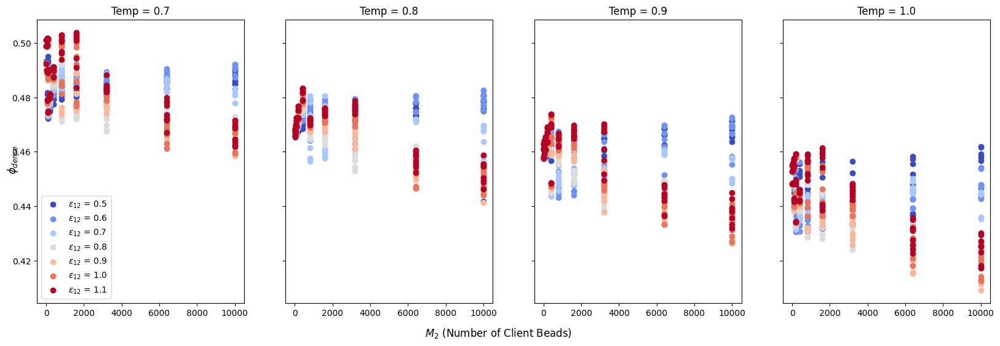

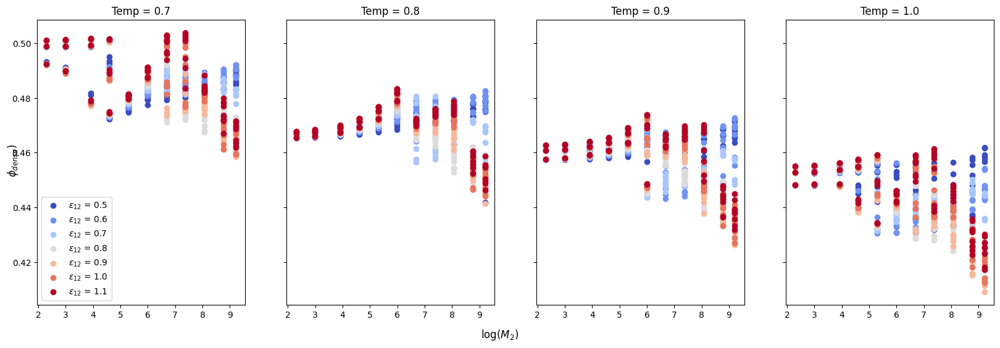

In [150]:
## Plotting N2/M2 vs. phi_all_dense
temperatures = [0.7, 0.8, 0.9, 1.0]
eps12_values = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1]
eps12 = data['eps12']
edgecols = plt.cm.coolwarm(np.linspace(0, 1, len(eps12_values)))
fig1, axes1 = plt.subplots(1, 4, figsize=(20, 6), sharey=True)
fig2, axes2 = plt.subplots(1, 4, figsize=(20, 6), sharey=True)
fig3, axes3 = plt.subplots(1, 4, figsize=(20, 6), sharey=True)
for i, temp_screen in enumerate(temperatures):
    ax1 = axes1[i]
    ax2 = axes2[i]
    ax3 = axes3[i]
    
    for eps, edge in zip(eps12_values, edgecols):
        mask = np.where( (temp == temp_screen) & (eps12 == eps) )
        ax1.scatter(N2[mask], phi_all_dense[mask], label=rf'$\epsilon_{{12}}$ = {eps}', color=edge)
        ax1.set_title(f'Temp = {temp_screen}')
    
        ax2.scatter(M2[mask], phi_all_dense[mask], label=rf'$\epsilon_{{12}}$ = {eps}', color=edge)
        ax2.set_title(f'Temp = {temp_screen}')

        ax3.scatter(np.log(M2[mask]), phi_all_dense[mask], label=rf'$\epsilon_{{12}}$ = {eps}', color=edge)
        ax3.set_title(f'Temp = {temp_screen}')
    if i == 0:
        ax1.legend()
        ax2.legend()
        ax3.legend()

fig1.supxlabel(r'$N_2$ (Number of Client Chains)')
fig1.supylabel(r'$\phi_{dense}$', x=0.1)
fig2.supxlabel(r'$M_2$ (Number of Client Beads)')
fig2.supylabel(r'$\phi_{dense}$', x=0.1)
fig3.supxlabel(r'$\log(M_2)$')
fig3.supylabel(r'$\phi_{dense})$', x=0.1)

fig1.savefig(f"../2-Plots/3_4a_N1_vs_phialldense_colTemp.png")
fig2.savefig(f"../2-Plots/3_4b_M1_vs_phialldense_colTemp.png")
fig2.savefig(f"../2-Plots/3_4c_logM1_vs_phialldense_colTemp.png")
plt.show()

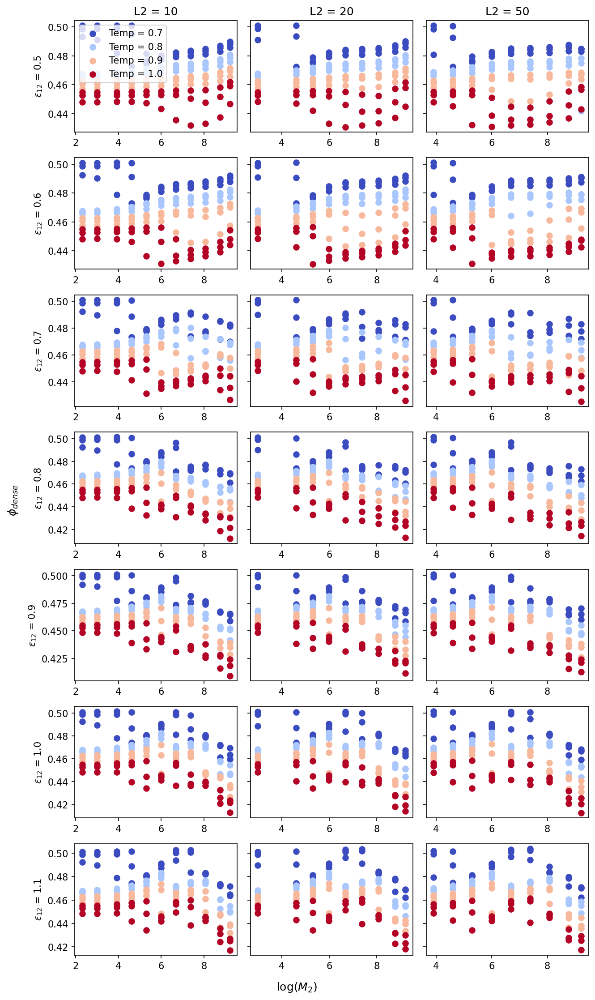

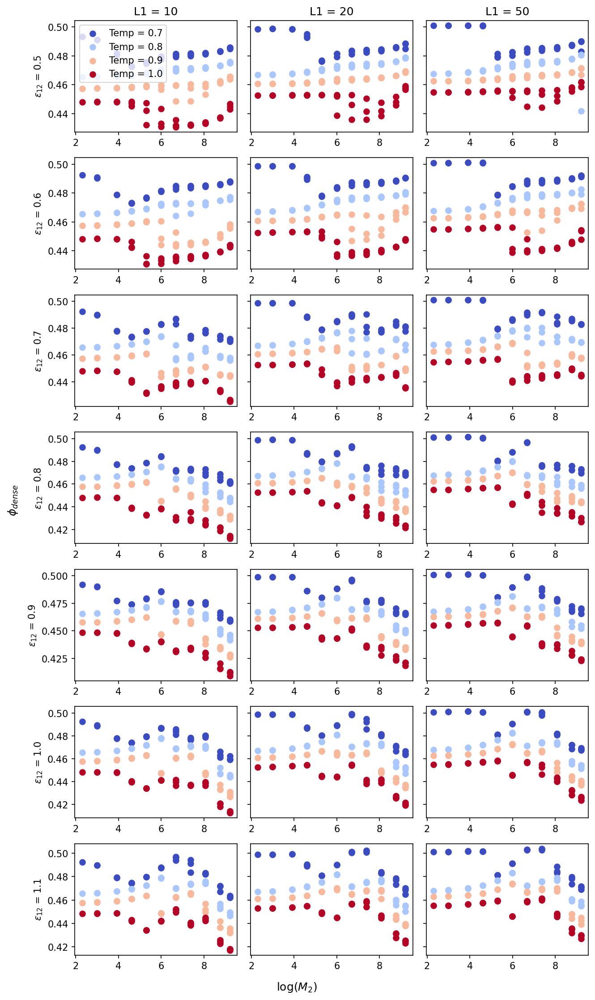

In [144]:
temperatures = [0.7, 0.8, 0.9, 1.0]
L1s = [10, 20, 50]
L2s = [10, 20, 50]
edgecols = plt.cm.coolwarm(np.linspace(0, 1, len(temperatures)))

fig1, axes1 = plt.subplots(7, 3, figsize=(9, 15), dpi=150, sharey='row')
fig2, axes2 = plt.subplots(7, 3, figsize=(9, 15), dpi=150, sharey='row')
for temp_screen, edge in zip(temperatures, edgecols):
    for i, eps in enumerate(eps12_values):
        for j, [l1, l2] in enumerate(zip(L1s, L2s)):
            ax1 = axes1[i, j]
            ax2 = axes2[i, j]
            mask1 = np.where( (temp == temp_screen) & (eps12 == eps) & (L2 == l2) )
            ax1.scatter(np.log(M2[mask1]), phi_all_dense[mask1], label=f'Temp = {temp_screen}', color=edge)
            mask2 = np.where( (temp == temp_screen) & (eps12 == eps) & (L1 == l1) )
            ax2.scatter(np.log(M2[mask2]), phi_all_dense[mask2], label=f'Temp = {temp_screen}', color=edge)
            if j == 0:
                ax1.set_ylabel(rf"$\epsilon_{{12}}$ = {eps}")
                ax2.set_ylabel(rf"$\epsilon_{{12}}$ = {eps}")
            if i == 0:
                ax1.set_title(f"L2 = {l2}")
                ax2.set_title(f"L1 = {l1}")
            if ( (i == 0) & (j == 0) ):
                ax1.legend()
                ax2.legend()
    fig1.supxlabel(r'$\log(M_2)$')
    fig1.supylabel(r'$\phi_{dense}$')
    fig2.supxlabel(r'$\log(M_2)$')
    fig2.supylabel(r'$\phi_{dense}$')
    fig1.tight_layout()
    fig2.tight_layout()
fig1.savefig("../2-Plots/3_5a_logM2_vs_phialldense_colL2.png")
fig2.savefig("../2-Plots/3_5b_logM2_vs_phialldense_colL1.png")
plt.show()